# [실습] 차원 축소, 이상 탐지, 장바구니 분석 — 정답 없는 데이터에서 패턴 찾기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 7 실습. 패턴과 이상은 데이터의 구조인가, 내가 고른 기준인가?

**필수 머신러닝 · Chapter 7**

| Part | 주제 |
| --- | --- |
| Part 1 | 차원 축소: 거래처 440곳의 지도 |
| Part 2 | 이상 탐지: 무엇에 비해 이상한가 |
| Part 3 | 장바구니 분석: 함께 팔리는 상품 |
| Part 4 | 영업기획팀에 보고하기 |

## 분석 의뢰서

> **의뢰 부서**: 유통사 영업기획팀 (오프라인 도매 거래처와 온라인몰을 함께 관리), 제휴 카드사 리스크팀
> **목적**: 두 팀이 가진 데이터에서 눈으로는 보이지 않는 패턴과 이상을 찾고 싶다.
> **제약**: 찾아낸 내용은 사람이 확인하고 행동으로 옮겨야 한다. 확인할 수 있는 인력은 한정되어 있다.
> **질문**: ① 거래처 440곳의 구매 패턴을 한눈에 볼 수 있는 지도를 만들 수 있나? ② 확인이 필요한 "이상한" 거래처와 카드 거래를 골라낼 수 있나? ③ 온라인몰에서 함께 팔리는 상품을 찾아 묶음 진열과 추천에 쓸 수 있나?

## 이 실습의 질문

> **영업기획팀에 "확인이 필요한 거래처 10곳"과 "함께 진열할 상품 5쌍"을 추천한다면, 각각 무엇을 기준으로 골랐고, 그 기준이 바뀌면 목록이 얼마나 바뀌는가?**

세 Part 모두 같은 순서로 진행합니다. 방법을 적용하고 → **전처리와 기준을 바꿔 결과가 얼마나 흔들리는지** 보고 → 결과를 **쓰지 않은 정보로** 확인합니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |
| **먼저 예상하기** | 결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다 |

## 준비

| 파일 | 크기 | 쓰는 곳 |
| --- | --- | --- |
| `wholesale.csv` (Wholesale Customers) | 약 15KB | Part 1, 2 |
| `creditcard.csv` (Credit Card Fraud Detection) | **약 103MB** | Part 2 (2-4) |
| `online_retail_II.csv` (Chapter 6과 같음) | **약 97MB** | Part 3 |

큰 파일 두 개는 Colab에 직접 올리기보다 Google Drive에 올려 두고 연결해 읽는 것을 권합니다(교안 0-5). 장바구니 분석에는 `mlxtend`가 필요합니다. 없다면 먼저 설치하세요(`pip install mlxtend`).

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_auc_score, average_precision_score
from mlxtend.frequent_patterns import apriori, association_rules

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# [환경] 그래프 한글 글꼴 등록 (같은 폴더의 fonts/NanumGothic-Regular.ttf)
import os
import matplotlib.font_manager as fm
for _p in ["fonts/NanumGothic-Regular.ttf", "../fonts/NanumGothic-Regular.ttf", "NanumGothic-Regular.ttf"]:
    if os.path.exists(_p):
        fm.fontManager.addfont(_p)
        plt.rcParams["font.family"] = fm.FontProperties(fname=_p).get_name()
        break
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 차원 축소: 거래처 440곳의 지도

## 1-1. 데이터와 겹치는 정보

**[제공]** 거래처 440곳의 6개 품목 연간 구매액입니다. 판매 채널(`Channel`: 1 = 호텔·식당·카페, 2 = 소매점)은 Part 1에서 **일부러 쓰지 않고** 남겨 두었다가 1-5에서 결과를 확인하는 데 씁니다.

In [3]:
# [제공] 데이터 불러오기
ws = pd.read_csv("wholesale.csv")
items = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]
print(ws.shape, "| 판매 채널:", ws["Channel"].value_counts().to_dict())
ws[items].describe().round(0)

(440, 8) | 판매 채널: {1: 298, 2: 142}


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


**[직접 작성]** 6개 품목 사이의 상관계수 표를 소수 둘째 자리까지 출력하세요.

In [4]:
corr = ws[items].corr().round(2)
corr

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Fresh,1.00,0.10,-0.01,0.35,-0.10,0.24
Milk,0.10,1.00,0.73,0.12,0.66,0.41
Grocery,-0.01,0.73,1.00,-0.04,0.92,0.21
Frozen,0.35,0.12,-0.04,1.00,-0.13,0.39
Detergents_Paper,-0.10,0.66,0.92,-0.13,1.00,0.07
Delicatessen,0.24,0.41,0.21,0.39,0.07,1.00


> **[판단]** 상관계수가 가장 높은 품목 쌍은 무엇인가요? 이 결과는 "여섯 개의 숫자를 모두 볼 필요가 없다"는 근거가 될 수 있나요?
>
> 나의 답:

가장 높은 상관은 **식료품(Grocery) ↔ 세제·종이(Detergents_Paper) 0.92**이고, 다음이 Milk↔Grocery 0.73, Milk↔Detergents 0.66입니다. 반대로 Fresh↔Grocery는 -0.01, Detergents↔Frozen은 -0.13으로 거의 무관합니다. 이 결과는 "여섯 개를 모두 볼 필요가 없다"의 **근거가 될 수 있지만 충분하지는 않습니다**. 세 품목(Grocery·Milk·Detergents)이 사실상 한 덩어리로 움직인다는 것은 맞지만, 상관계수는 **선형 관계**만 재므로 "같이 사는가"의 크기 차이(예: 소매점은 셋 다 크고, 식당은 Fresh만 큼)를 담지 못합니다. 실제로 PCA를 해 보면 두 축으로 71%만 설명됩니다(1-3).


## 1-2. 전처리가 축을 정한다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 신선식품의 표준편차는 약 12,600으로 여섯 품목 중 가장 큽니다.

> **[판단]** 예상: 원본 그대로 PCA를 하면 첫 번째 주성분(PC1)은 어떤 품목이 주로 만들까요?
>
> 나의 답:

예상: 원본 그대로 PCA를 하면 PC1은 **신선식품(Fresh)** 이 주로 만들 것 같습니다. 표준편차가 12,647로 여섯 품목 중 가장 커서, 분산을 가장 많이 설명하는 방향이 Fresh가 되기 쉽기 때문입니다.


**[직접 작성]** 세 가지 전처리로 PCA를 하고, 각각 PC1과 PC2의 설명 분산 비율, PC1의 가중치를 출력하세요.

1. 원본 그대로
2. 표준화만 (`StandardScaler`)
3. 로그 변환(`np.log1p`) 뒤 표준화

<details><summary>힌트</summary>

```python
pca = PCA().fit(X)
pca.explained_variance_ratio_[:2]     # 설명 분산 비율
pca.components_[0]                    # PC1의 가중치 (품목 순서는 items와 같음)
```
</details>

In [5]:
X_raw7 = ws[items].values
X_std7 = StandardScaler().fit_transform(X_raw7)
X_log = StandardScaler().fit_transform(np.log1p(X_raw7))

def pca_report(X, label):
    p = PCA().fit(X)
    print(f"[{label}] PC1 {p.explained_variance_ratio_[0]:.3f} | PC2 {p.explained_variance_ratio_[1]:.3f} | 누적 {p.explained_variance_ratio_[:2].sum():.3f}")
    print(pd.Series(p.components_[0], index=items).round(3).to_string())
    print()
    return p

pca_raw = pca_report(X_raw7, "원본 그대로")
pca_std = pca_report(X_std7, "표준화만")
pca_log = pca_report(X_log, "로그 + 표준화")

[원본 그대로] PC1 0.460 | PC2 0.405 | 누적 0.865
Fresh               0.977
Milk                0.121
Grocery             0.062
Frozen              0.152
Detergents_Paper   -0.007
Delicatessen        0.068

[표준화만] PC1 0.441 | PC2 0.284 | 누적 0.725
Fresh               0.043
Milk                0.545
Grocery             0.579
Frozen              0.051
Detergents_Paper    0.549
Delicatessen        0.249

[로그 + 표준화] PC1 0.441 | PC2 0.272 | 누적 0.713
Fresh              -0.105
Milk                0.542
Grocery             0.571
Frozen             -0.138
Detergents_Paper    0.551
Delicatessen        0.214



> **[판단]** 예상은 맞았나요? 원본 그대로의 PC1은 품목들의 관계를 요약한 축인가요, 아니면 다른 것인가요? 누적 설명 분산이 가장 높은 전처리가 가장 좋은 요약인가요?
>
> 나의 답:

예상이 맞았습니다. 원본 그대로에서 PC1의 가중치는 **Fresh 0.977**이고 나머지는 0.15 이하입니다. 즉 PC1은 "품목들의 관계를 요약한 축"이 아니라 **사실상 Fresh의 크기**입니다. 분산이 큰 변수가 축을 독점하는 것입니다. 표준화하면 PC1이 Milk 0.545·Grocery 0.579·Detergents 0.549로 세 품목에 고르게 걸리고, 로그+표준화도 같습니다. 누적 설명 분산이 가장 높은 것은 원본(0.865)이지만 **가장 좋은 요약은 아닙니다**. 0.865 중 대부분이 Fresh 하나의 분산이고, 나머지 품목의 관계는 버려집니다. 요약의 품질은 "설명 분산"이 아니라 "축이 무엇을 뜻하는가"로 판단해야 합니다.


## 1-3. 몇 개의 축을 남기고, 어떻게 이름 붙이나

이제부터 로그 + 표준화한 `X_log`를 씁니다.

**[직접 작성]** 세 가지를 출력하세요.

1. 성분 6개의 설명 분산 비율과 누적 비율
2. PC1과 PC2의 품목별 가중치 표
3. 성분을 1, 2, 3, 6개 남겼을 때의 재구성 오차(표준화된 값 기준 평균 제곱 오차)

<details><summary>힌트</summary>

재구성 오차는 성분 $k$개로 줄였다가 되돌린 값과 원래 값의 차이입니다.
```python
p = PCA(n_components=k).fit(X_log)
X_back = p.inverse_transform(p.transform(X_log))
((X_log - X_back) ** 2).mean()
```
</details>

In [6]:
pca_full = PCA().fit(X_log)
ev = pd.DataFrame({"설명 분산 비율": pca_full.explained_variance_ratio_.round(3),
                   "누적 비율": np.cumsum(pca_full.explained_variance_ratio_).round(3)},
                  index=[f"PC{i}" for i in range(1, 7)])
print("[로그+표준화 설명 분산]")
print(ev)
print()
print("[PC1·PC2 가중치]")
print(pd.DataFrame({"PC1": pca_full.components_[0], "PC2": pca_full.components_[1]}, index=items).round(3))
print()
print("[성분 개수별 재구성 오차 (표준화 값 기준 MSE)]")
for k in [1, 2, 3, 6]:
    p = PCA(n_components=k).fit(X_log)
    back = p.inverse_transform(p.transform(X_log))
    print(f"  {k}개: {((X_log - back) ** 2).mean():.3f}")

[로그+표준화 설명 분산]
     설명 분산 비율  누적 비율
PC1     0.441  0.441
PC2     0.272  0.713
PC3     0.107  0.820
PC4     0.101  0.921
PC5     0.049  0.970
PC6     0.030  1.000

[PC1·PC2 가중치]
                    PC1    PC2
Fresh            -0.105  0.590
Milk              0.542  0.133
Grocery           0.571 -0.006
Frozen           -0.138  0.590
Detergents_Paper  0.551 -0.071
Delicatessen      0.214  0.530

[성분 개수별 재구성 오차 (표준화 값 기준 MSE)]
  1개: 0.559
  2개: 0.287
  3개: 0.180
  6개: 0.000


> **[판단]** 시각화를 위해 두 축만 남기면 정보가 얼마나 남나요? PC1과 PC2의 가중치를 읽어 각 축에 이름을 붙여 보세요. (가중치의 부호는 뒤집혀 나올 수 있으니 "어떤 품목들이 같은 부호로 함께 큰가"를 보세요.)
>
> 나의 답:

두 축(PC1·PC2)만 남기면 정보의 **71.3%**가 남습니다(PC1 44.1% + PC2 27.2%). 재구성 오차(표준화 값 기준 MSE)는 1개 0.559, 2개 **0.287**, 3개 0.180, 6개 0.000입니다. 즉 2개로 줄이면 평균적으로 표준화 값의 약 0.54만큼(√0.287) 틀립니다.
가중치를 읽어 이름을 붙이면, **PC1 = 유제품·식료품·세제(0.542·0.571·0.551, 신선·냉동은 음수)** 로 "가공식품·생활용품 구매 규모"입니다. **PC2 = 신선(0.590)·냉동(0.590)·델리(0.530)** 로 "신선·냉동·델리 구매 규모"입니다. 두 축은 대체로 **"가공·생활용품 vs 신선·조리재료"** 의 대비로 읽힙니다.


## 1-4. 쓰지 않은 정보로 이름 확인하기

**[직접 작성]** 세 가지를 하세요.

1. 거래처마다 PC1, PC2 점수를 계산하고(`pca.transform(X_log)[:, :2]`), 판매 채널별 평균을 출력
2. 판매 채널(소매점 = 1)을 맞히는 로지스틱 회귀의 5겹 교차검증 ROC AUC를 세 가지 입력으로 비교: 여섯 품목 전부(`X_log`), PC1 하나, PC1 + PC2
3. PC1(가로)과 PC2(세로)로 산점도를 그리고, 점의 색을 판매 채널로 칠하기

<details><summary>힌트</summary>

교차검증은 `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, 입력이 한 열일 때는 `scores[:, :1]`처럼 2차원으로 넣습니다.
</details>

[판매 채널별 PC 점수 평균]
          PC1   PC2
Channel            
1       -0.81  0.11
2        1.70 -0.22
  여섯 품목 전부: ROC AUC 0.964 ± 0.009


  PC1 하나: ROC AUC 0.956 ± 0.009
  PC1 + PC2: ROC AUC 0.955 ± 0.011


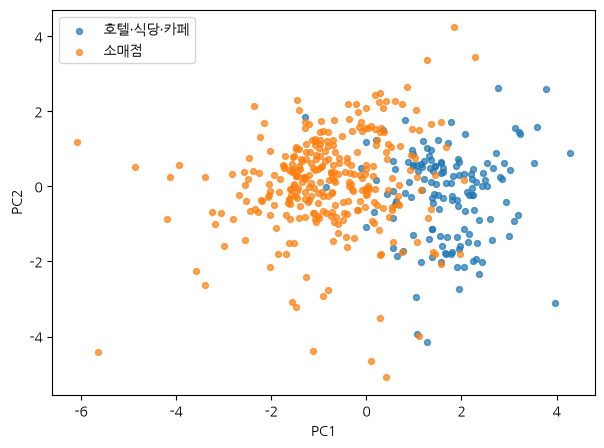

In [7]:
pca2 = PCA(n_components=2).fit(X_log)
scores = pca2.transform(X_log)
ws_scores = pd.DataFrame(scores, columns=["PC1", "PC2"], index=ws.index)
ws_scores["Channel"] = ws["Channel"].values
print("[판매 채널별 PC 점수 평균]")
print(ws_scores.groupby("Channel")[["PC1", "PC2"]].mean().round(2))

y_ch = (ws["Channel"] == 1).astype(int).values
cv7 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, X_in in [("여섯 품목 전부", X_log), ("PC1 하나", scores[:, :1]), ("PC1 + PC2", scores)]:
    s = cross_val_score(LogisticRegression(max_iter=2000), X_in, y_ch, cv=cv7, scoring="roc_auc")
    print(f"  {name}: ROC AUC {s.mean():.3f} ± {s.std():.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
for ch, label, color in [(2, "호텔·식당·카페", "tab:blue"), (1, "소매점", "tab:orange")]:
    part = ws_scores[ws_scores["Channel"] == ch]
    ax.scatter(part["PC1"], part["PC2"], s=18, alpha=0.7, label=label, color=color)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
plt.show()

> **[판단]** 1-3에서 붙인 PC1, PC2의 이름은 판매 채널로 확인되나요? 숫자 여섯 개 대신 PC1 하나를 써도 채널을 가르는 힘이 얼마나 남나요? 확인되지 않은 축의 이름은 보고서에 어떻게 적겠습니까?
>
> 나의 답:

PC1, PC2의 이름은 판매 채널로 **부분적으로 확인됩니다**. 채널별 PC1 평균은 소매점 **1.70**, 호텔·식당·카페 **-0.81**로 뚜렷이 갈립니다(소매점은 가공식품·생활용품을 많이 산다). PC2는 소매점 -0.22, 호텔·식당 0.11로 차이가 작습니다. 산점도에서도 소매점(주황)이 PC1 오른쪽에 모여 있고, 호텔·식당(파랑)은 왼쪽에 넓게 퍼집니다.
숫자 여섯 개 대신 **PC1 하나**만 써도 채널을 가르는 힘은 거의 그대로 남습니다. 여섯 품목 전부 0.964, **PC1 하나 0.956**, PC1+PC2 0.955입니다. 즉 채널 구분에 필요한 정보는 PC1에 거의 다 들어 있고, PC2는 채널과 무관한 다른 구조(신선·냉동의 규모)입니다.
확인되지 않은 축(PC2)의 이름은 보고서에 **"신선·냉동 구매 규모(채널로는 확인되지 않음, 거래처 성격 추정)"** 처럼 적고, "외식형" 같은 단정은 쓰지 않겠습니다. 이름은 해석이지 검증된 사실이 아닙니다.


---
# Part 2. 이상 탐지: 무엇에 비해 이상한가

## 2-1. 사람의 규칙: IQR

**[직접 작성]** 로그 변환한 구매액(`np.log1p(ws[items])`)에 품목별로 IQR 규칙을 적용해, 품목별 이상치 거래처 수, **한 품목이라도** 걸리는 거래처 수, **두 품목 이상**에서 걸리는 거래처 수를 출력하세요.

IQR 규칙: $x < Q_1 - 1.5 \times \text{IQR}$ 또는 $x > Q_3 + 1.5 \times \text{IQR}$

<details><summary>힌트</summary>

```python
L = np.log1p(ws[items])
q1, q3 = L.quantile(0.25), L.quantile(0.75)
iqr = q3 - q1
out = (L < q1 - 1.5 * iqr) | (L > q3 + 1.5 * iqr)     # 거래처 × 품목의 True/False 표
```
</details>

In [8]:
L = np.log1p(ws[items])
q1, q3 = L.quantile(0.25), L.quantile(0.75)
iqr = q3 - q1
out = (L < q1 - 1.5 * iqr) | (L > q3 + 1.5 * iqr)
print("[품목별 IQR 이상치 거래처 수]")
print(out.sum().to_string())
print()
print("한 품목이라도 걸린 거래처:", int(out.any(axis=1).sum()))
print("두 품목 이상 걸린 거래처:", int((out.sum(axis=1) >= 2).sum()))

[품목별 IQR 이상치 거래처 수]
Fresh               16
Milk                 4
Grocery              2
Frozen              10
Detergents_Paper     2
Delicatessen        14

한 품목이라도 걸린 거래처: 42
두 품목 이상 걸린 거래처: 5


> **[판단]** "한 품목이라도"와 "두 품목 이상" 중 어느 기준을 쓸지는 무엇이 정하나요? 품목을 하나씩 보는 IQR 규칙이 놓치는 이상은 어떤 것일까요?
>
> 나의 답:

기준은 **"무엇을 찾으려는 목록인가"** 가 정합니다. 입력 오류(예: 3과 300의 자리 오류)를 찾으려면 "한 품목만 유난히 튀는" 거래처를 봐야 하므로 **"한 품목이라도"(42곳)** 가 맞습니다. 반대로 "무언가 이상한 거래처"를 넓게 보고 싶으면 "두 품목 이상"(5곳)이 정밀합니다. 즉 1건이라도 걸리면 42곳(9.5%)이고, 2건 이상은 5곳으로 확인 인력에 맞춰 고릅니다.
품목을 하나씩 보는 IQR은 **조합의 이상**을 놓칩니다. 예를 들어 338번 거래처(Fresh 3, Milk 333, Grocery 7,021, Frozen 15,601)는 각 품목이 정상 범위 안이지만, "신선식품을 거의 안 사면서 냉동·식료품만 크게 사는" 조합이 이상합니다. IQR은 각 축을 따로 보므로 이런 **관계의 이상**을 잡지 못합니다. 그래서 다음 절의 다변량 방법이 필요합니다.


## 2-2. Isolation Forest: 전처리가 "이상"의 뜻을 바꾼다

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 같은 Isolation Forest를 (가) 로그 + 표준화한 데이터, (나) 표준화만 한 원본 규모의 데이터에 적용해 가장 이상한 10곳을 뽑습니다.

> **[판단]** 예상: 두 목록의 상위 10곳은 몇 곳이나 겹칠까요? 각 목록에는 어떤 거래처가 많이 들어갈까요?
>
> 나의 답:

예상: 두 목록의 상위 10곳은 **3~5곳** 정도 겹칠 것 같습니다. 로그 기준 목록에는 **특정 품목을 거의 사지 않는 작은 거래처**(154번 Fresh 622·Detergents 7, 161번 Detergents 3)가, 표준화만 기준 목록에는 **전체적으로 큰 거래처**(181번 Fresh 112,151, 85번 Grocery 92,780)가 많이 들어갈 것으로 봤습니다.


**[직접 작성]** `IsolationForest(n_estimators=200, random_state=42)`로 두 데이터의 이상 점수를 계산하고(`-model.score_samples(X)`, 클수록 이상), 각각 상위 10곳의 채널과 6개 품목 구매액을 출력하세요. 두 목록에서 겹치는 거래처 수도 출력합니다.

<details><summary>힌트</summary>

`top = np.argsort(-score)[:10]`으로 상위 10곳의 행 번호를 얻고, `ws.iloc[top]`으로 그 거래처를 봅니다. 겹치는 수는 `len(set(top_a) & set(top_b))`.
</details>

In [9]:
X_std_only = StandardScaler().fit_transform(ws[items].values)
iso_log = IsolationForest(n_estimators=200, random_state=42).fit(X_log)
iso_std = IsolationForest(n_estimators=200, random_state=42).fit(X_std_only)
score_log = -iso_log.score_samples(X_log)
score_std = -iso_std.score_samples(X_std_only)

top_log = np.argsort(-score_log)[:10]
top_std = np.argsort(-score_std)[:10]

cols = ["Channel"] + items
print("[로그+표준화 기준 상위 10곳]")
print(ws.iloc[top_log][cols].round(0).to_string())
print()
print("[표준화만 기준 상위 10곳]")
print(ws.iloc[top_std][cols].round(0).to_string())
print()
print("두 목록이 겹치는 거래처 수:", len(set(top_log) & set(top_std)))

[로그+표준화 기준 상위 10곳]
     Channel  Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
154        1    622     55      137      75                 7             8
338        1      3    333     7021   15601                15           550
183        1  36847  43950    20170   36534               239         47943
75         1  20398   1137        3    4407                 3           975
65         2     85  20959    45828      36             24231          1423
142        1  37036   7152     8253    2995                20             3
47         2  44466  54259    55571    7782             24171          6465
161        1  12434    540      283    1092                 3          2233
356        1  22686    134      218    3157                 9           548
289        1  42786    286      471    1388                32            22

[표준화만 기준 상위 10곳]
     Channel   Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
183        1   36847  43950    20170   36534      

> **[판단]** 두 목록의 거래처는 각각 어떤 성격인가요? (중앙값 거래처: 신선 8,504, 유제품 3,627, 식료품 4,756, 냉동 1,526, 세제·종이 816, 델리 966) 입력 오류를 찾고 싶을 때와 대형 거래처를 찾고 싶을 때 각각 어느 기준을 쓰겠습니까?
>
> 나의 답:

예상이 맞았습니다. 로그 기준 상위 10곳에는 154번(Fresh 622, 세제 7), 161번(Fresh 12,434, 세제 3), 289번(세제 32)처럼 **특정 품목을 거의 사지 않는** 거래처가 많고, 표준화만 기준에는 181번(Fresh 112,151), 85번(Grocery 92,780), 47번(Fresh 44,466·Milk 54,259)처럼 **규모가 큰** 거래처가 들어갑니다. 겹치는 곳은 **3곳**뿐입니다.
입력 오류를 찾고 싶을 때는 **로그 기준**(작은 값·비정상 조합이 드러남)을, 대형 거래처(우량 고객)를 찾고 싶을 때는 **표준화만 기준**(큰 값이 이상으로 잡힘)을 씁니다. 같은 "이상"이라는 말이 전처리에 따라 **"입력 오류"와 "핵심 고객"** 으로 뒤집힙니다. 중앙값 거래처(신선 8,504, 유제품 3,627, 식료품 4,756, 냉동 1,526, 세제 816, 델리 966)와 비교해 보면 이 차이가 분명합니다.


## 2-3. 방법마다 다른 "이상"

**[직접 작성]** `X_log`에 두 가지 방법을 더 적용해 상위 10곳을 뽑고, 2-2의 (가) 목록과 서로 겹치는 수를 출력하세요.

1. LOF: `-LocalOutlierFactor(n_neighbors=20).fit(X_log).negative_outlier_factor_` (클수록 이상)
2. PCA 재구성 오차: 성분 2개로 줄였다 되돌린 값과 원래 값의 차이 제곱합 (거래처마다)

In [10]:
lof = LocalOutlierFactor(n_neighbors=20).fit(X_log)
score_lof = -lof.negative_outlier_factor_
top_lof = np.argsort(-score_lof)[:10]

pca2b = PCA(n_components=2).fit(X_log)
recon = ((X_log - pca2b.inverse_transform(pca2b.transform(X_log))) ** 2).sum(axis=1)
top_recon = np.argsort(-recon)[:10]

print("[LOF 상위 10곳]")
print(ws.iloc[top_lof][["Channel"] + items].round(0).to_string())
print()
print("[PCA 재구성 오차 상위 10곳]")
print(ws.iloc[top_recon][["Channel"] + items].round(0).to_string())
print()
print("(가) 로그 Isolation Forest와 겹치는 수: LOF", len(set(top_log) & set(top_lof)),
      "| 재구성 오차", len(set(top_log) & set(top_recon)),
      "| LOF와 재구성", len(set(top_lof) & set(top_recon)))

[LOF 상위 10곳]
     Channel  Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
75         1  20398   1137        3    4407                 3           975
338        1      3    333     7021   15601                15           550
154        1    622     55      137      75                 7             8
142        1  37036   7152     8253    2995                20             3
183        1  36847  43950    20170   36534               239         47943
429        1   8607   1750     3580      47                84          2501
161        1  12434    540      283    1092                 3          2233
204        1   1956    891     5226    1383                 5          1328
71         1  18291   1266    21042    5373              4173         14472
289        1  42786    286      471    1388                32            22

[PCA 재구성 오차 상위 10곳]
     Channel  Fresh   Milk  Grocery  Frozen  Detergents_Paper  Delicatessen
338        1      3    333     7021   15601           

> **[판단]** 세 방법의 목록이 서로 다른 이유는 무엇인가요? 확인 인력이 한정되어 있다면 여러 방법의 결과를 어떻게 함께 쓰겠습니까?
>
> 나의 답:

세 방법의 목록이 다른 이유는 **"이상"의 정의가 다르기** 때문입니다. LOF는 **주변 이웃과의 밀도**를 보므로 "혼자 떨어진" 거래처(75번 Fresh 20,398인데 Grocery 3)를 잡고, PCA 재구성 오차는 **두 축으로 설명되지 않는** 거래처(338번: 신선 3·냉동 15,601)를 잡습니다. Isolation Forest는 **무작위 분할로 빨리 고립되는** 점을 잡습니다. (가) 로그 Isolation Forest와 겹치는 수는 LOF **7곳**, 재구성 오차 **3곳**으로, LOF와 가장 비슷합니다.
확인 인력이 한정되어 있다면 이렇게 쓰겠습니다. ⑴ **여러 방법에 공통으로 나온 곳을 먼저** 확인한다(예: 75·338·142·183번은 세 방법 중 둘 이상에 등장). ⑵ 그다음 "무엇을 찾는지"에 맞는 한 방법을 골라 목록을 채운다(입력 오류 → 로그+Isolation Forest, 구조적 이상 → 재구성 오차). ⑶ 방법별 목록의 **개수를 미리 정해** 인력에 맞춘다. 여러 방법을 단순히 합치면 목록이 10곳이 아니라 25곳이 되어 확인할 수 없습니다.


## 2-4. 정답이 있을 때 확인하기: 카드 사기 데이터

카드 거래 데이터에는 거래마다 사기 여부(`Class`)가 있습니다. 이 정답을 **학습에는 쓰지 않고** Isolation Forest를 돌린 뒤, 정답과 비교해 "정답 없이 찾은 이상치가 실제 사기를 얼마나 잡는가"를 확인합니다.

**[제공]** 큰 파일이므로 필요한 열만, 숫자는 32비트로 읽습니다(교안 0-5).

In [11]:
# [제공] 카드 거래 데이터 읽기 (필요한 열만, float32)
card_cols = [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]
card = pd.read_csv("creditcard.csv", usecols=card_cols, dtype={c: "float32" for c in card_cols[:-1]})
print(card.shape, "| 사기", int(card["Class"].sum()), "건 (", round(card["Class"].mean() * 100, 3), "% )",
      "| 메모리", round(card.memory_usage(deep=True).sum() / 1e6, 1), "MB")

(284807, 30) | 사기 492 건 ( 0.173 % ) | 메모리 35.3 MB


**[직접 작성]**

1. `Class`를 뺀 피처로 `IsolationForest(n_estimators=200, random_state=42, n_jobs=-1)`를 학습하고 이상 점수를 계산하세요.
2. 이상 점수 상위 $N$건($N$ = 100, 500, 1,000, 5,000) 중 실제 사기 수, 정밀도, 무작위로 $N$건을 골랐을 때의 기대 사기 수를 표로 출력하세요.
3. ROC AUC와 PR AUC를 출력하세요.
4. 비교를 위해 "금액이 큰 순서로 1,000건"이라는 단순한 규칙의 사기 수와, 사기·정상 거래의 금액 중앙값을 출력하세요.

In [12]:
feat_cols = [c for c in card.columns if c != "Class"]
iso_card = IsolationForest(n_estimators=200, random_state=42, n_jobs=1).fit(card[feat_cols].values)
score_card = -iso_card.score_samples(card[feat_cols].values)
y_card = card["Class"].values

order_card = np.argsort(-score_card)
rows = []
base_rate = y_card.mean()
for N in [100, 500, 1000, 5000]:
    hits = int(y_card[order_card[:N]].sum())
    rows.append({"상위 N건": N, "실제 사기": hits, "정밀도": round(hits / N, 4),
                 "무작위 기대 사기": round(N * base_rate, 1), "무작위 대비": round(hits / (N * base_rate), 1)})
print(pd.DataFrame(rows).to_string(index=False))
print()
print("ROC AUC:", round(roc_auc_score(y_card, score_card), 3), "| PR AUC:", round(average_precision_score(y_card, score_card), 3))
print()
big = np.argsort(-card["Amount"].values)[:1000]
print("금액 상위 1,000건의 사기 수:", int(y_card[big].sum()))
print("사기 거래 금액 중앙값:", round(float(card.loc[card["Class"] == 1, "Amount"].median()), 1),
      "| 정상 거래 금액 중앙값:", round(float(card.loc[card["Class"] == 0, "Amount"].median()), 1))

 상위 N건  실제 사기    정밀도  무작위 기대 사기  무작위 대비
   100     39 0.3900        0.2   225.8
   500    138 0.2760        0.9   159.8
  1000    189 0.1890        1.7   109.4
  5000    343 0.0686        8.6    39.7

ROC AUC: 0.948 | PR AUC: 0.164

금액 상위 1,000건의 사기 수: 2
사기 거래 금액 중앙값: 9.2 | 정상 거래 금액 중앙값: 22.0


> **[판단]** 정답을 한 번도 보지 않았는데 상위 100건 중 몇 건이 사기였나요? 무작위의 몇 배인가요? "큰 금액 = 수상하다"는 직관은 이 데이터에서 맞았나요?
>
> 나의 답:

정답을 한 번도 보지 않았는데 **상위 100건 중 39건**이 사기였습니다. 무작위로 100건을 골랐다면 0.17건이므로 **약 226배**입니다. 상위 500건은 138건(159.8배), 1,000건은 189건(109.4배), 5,000건은 343건(39.7배)으로, 확인할수록 정밀도는 떨어지지만(39% → 6.9%) 여전히 무작위보다 훨씬 높습니다.
"큰 금액 = 수상하다"는 직관은 이 데이터에서 **틀렸습니다**. 금액 상위 1,000건의 사기 수는 **2건**뿐이고, 사기 거래의 금액 중앙값은 **9.2**, 정상 거래는 **22.0**으로 사기가 오히려 더 작습니다. 고액 결제는 대개 정상이고, 사기는 작은 금액으로 시험하는 경우가 많습니다.


> **[판단]** ROC AUC와 PR AUC 중 리스크팀에 어떤 숫자로 성과를 전하겠습니까? 하루 500건을 확인할 수 있다면 몇 건의 사기를 찾을 것으로 기대하나요? 사기 판정 기록이 쌓이면 무엇을 하는 것이 더 나을까요?
>
> 나의 답:

리스크팀에는 **PR AUC(0.164)** 를 먼저 전하겠습니다. 사기 비율이 0.173%인 극단적 불균형에서는 ROC AUC(0.948)가 좋아 보여도 실제 정밀도를 과대평가합니다(정상 거래가 압도적으로 많아 위양성을 조금만 내도 ROC는 높게 유지됩니다). PR AUC는 "사기라고 경보한 것 중 실제 사기"를 직접 반영합니다. 다만 PR AUC 0.164라는 숫자만으로는 감이 안 오니, **"상위 100건 중 39건(39%), 상위 500건 중 138건(27.6%)"** 처럼 업무 단위로 바꿔 전하겠습니다.
하루 500건을 확인할 수 있다면 **약 138건의 사기**를 찾을 것으로 기대합니다(무작위 0.9건의 160배). 사기 판정 기록이 쌓이면 새 이상치 탐지보다 **지도학습 모델(라벨을 쓴 분류기)** 을 만드는 것이 낫습니다. 지금은 정답이 없다고 가정한 탐지이고, 실제 라벨이 쌓이면 정밀도를 훨씬 높일 수 있습니다. 다만 라벨이 편향(확인한 것만 라벨이 됨)되어 있으니, 무작위 표본에도 라벨을 붙여 편향을 보정해야 합니다.


---
# Part 3. 장바구니 분석: 함께 팔리는 상품

## 3-1. 주문 × 상품 표 만들기

**[제공]** Online Retail II에서 영국 고객의 실제 구매 기록만 남기고, 배송비·수수료 같은 상품이 아닌 항목을 뺍니다. 그다음 주문 하나가 한 행, 상품 하나가 한 열인 True/False 표를 만드는 함수 `make_basket`을 정의합니다.

In [13]:
# [제공] 데이터 준비
raw = pd.read_csv("online_retail_II.csv", dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
non_product = ["POST", "DOT", "M", "C2", "BANK CHARGES", "ADJUST", "ADJUST2", "D", "PADS", "TEST001", "TEST002", "AMAZONFEE", "CRUK", "S", "B"]
uk = raw[raw["CustomerID"].notna() & ~raw["Invoice"].str.startswith("C") & (raw["Quantity"] > 0) & (raw["Price"] > 0)
         & (raw["Country"] == "United Kingdom") & ~raw["StockCode"].str.upper().isin(non_product)].copy()
uk["Description"] = uk["Description"].str.strip()
year1 = uk[(uk["InvoiceDate"] >= "2009-12-01") & (uk["InvoiceDate"] < "2010-12-01")]
year2 = uk[(uk["InvoiceDate"] >= "2010-12-01") & (uk["InvoiceDate"] < "2011-12-01")]
del raw    # 큰 원본은 지워 메모리를 아낀다

def make_basket(d):
    # 주문 × 상품: 그 주문에 그 상품이 있으면 True
    return d.groupby(["Invoice", "Description"]).size().unstack(fill_value=0) > 0
print("규칙을 찾을 해:", year1["Invoice"].nunique(), "건 주문 | 확인할 다음 해:", year2["Invoice"].nunique(), "건 주문")

규칙을 찾을 해: 16782 건 주문 | 확인할 다음 해: 15874 건 주문


**[직접 작성]** `make_basket(year1)`로 첫해의 주문 × 상품 표 `basket`을 만들고, 크기(주문 수 × 상품 종류 수), 주문당 상품 수의 평균과 중앙값, 가장 자주 나오는 상품 3개와 그 지지도, 표가 차지하는 메모리(MB)를 출력하세요.

In [14]:
basket = make_basket(year1)
print("크기:", basket.shape, "| 메모리", round(basket.memory_usage(deep=True).sum() / 1e6, 1), "MB")
per_order = basket.sum(axis=1)
print("주문당 상품 수 평균", round(per_order.mean(), 2), "| 중앙값", int(per_order.median()))
top3 = basket.mean().sort_values(ascending=False).head(3)
print("가장 자주 나오는 상품 3개 (지지도):")
print(top3.round(4).to_string())

크기: (16782, 4353) | 메모리 74.0 MB
주문당 상품 수 평균 20.55 | 중앙값 15
가장 자주 나오는 상품 3개 (지지도):
Description
WHITE HANGING HEART T-LIGHT HOLDER    0.1679
REGENCY CAKESTAND 3 TIER              0.0862
STRAWBERRY CERAMIC TRINKET BOX        0.0724


## 3-2. Apriori로 규칙 찾기

### 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다.

> **[판단]** 예상: 향상도가 가장 높은 규칙들은 어떤 상품 쌍일까요? (예: 서로 다른 범주의 의외의 조합 / 세트로 파는 상품)
>
> 나의 답:

예상: 향상도 상위 규칙은 **세트로 파는 상품**(어린이 정원 도구, 장난감 하우스 가구)일 것 같습니다. 같은 시리즈를 함께 사는 경향이 강해서, 서로 다른 범주의 의외의 조합보다 향상도가 훨씬 높을 것으로 봤습니다.


**[직접 작성]**

1. 지지도가 1% 이상인 상품만 남긴 표 `basket_freq`를 만드세요. 상품 4천여 종을 그대로 Apriori에 넣으면 메모리가 수 GB 필요합니다. 지지도 1% 미만 상품은 어차피 Apriori의 첫 단계에서 버려지므로 결과는 같습니다.
2. `apriori(basket_freq, min_support=0.01, use_colnames=True, low_memory=True)`로 자주 나오는 묶음을 찾고, 묶음 수와 그중 두 상품짜리 수를 출력하세요.
3. `association_rules(..., metric="lift", min_threshold=1.0)`로 규칙을 만들고, **상품 하나 → 하나** 규칙만 남겨 `rules`에 저장하세요. `rules`에 앞쪽 상품 `A`, 뒤쪽 상품 `B` 열을 만들고, 향상도 상위 6개를 출력합니다.

<details><summary>힌트</summary>

```python
rules = rules[(rules["antecedents"].apply(len) == 1) & (rules["consequents"].apply(len) == 1)].copy()
rules["A"] = rules["antecedents"].apply(lambda s: list(s)[0])
rules["B"] = rules["consequents"].apply(lambda s: list(s)[0])
```
</details>

In [15]:
support = basket.mean()
basket_freq = basket.loc[:, support >= 0.01]
print("지지도 1% 이상 상품 수:", basket_freq.shape[1], "/", basket.shape[1])

freq_items = apriori(basket_freq, min_support=0.01, use_colnames=True, low_memory=True)
print("자주 나오는 묶음:", len(freq_items), "| 두 상품짜리:", int((freq_items["itemsets"].apply(len) == 2).sum()))

all_rules = association_rules(freq_items, metric="lift", min_threshold=1.0)
single = all_rules[(all_rules["antecedents"].apply(len) == 1) & (all_rules["consequents"].apply(len) == 1)].copy()
single["A"] = single["antecedents"].apply(lambda s: next(iter(s)))
single["B"] = single["consequents"].apply(lambda s: next(iter(s)))
rules = single
print("상품 하나 → 하나 규칙:", len(rules))
rules.sort_values("lift", ascending=False).head(6)[["A", "B", "support", "confidence", "lift", "consequent support"]].round(3)

지지도 1% 이상 상품 수: 593 / 4353


자주 나오는 묶음: 858 | 두 상품짜리: 241
상품 하나 → 하나 규칙: 482


,A,B,support,confidence,lift,consequent support
65,CHILDS GARDEN TROWEL PINK,CHILDS GARDEN FORK PINK,0.01,0.817,75.363,0.011
64,CHILDS GARDEN FORK PINK,CHILDS GARDEN TROWEL PINK,0.01,0.934,75.363,0.012
67,CHILDS GARDEN TROWEL PINK,CHILDS GARDEN TROWEL BLUE,0.01,0.841,70.246,0.012
66,CHILDS GARDEN TROWEL BLUE,CHILDS GARDEN TROWEL PINK,0.01,0.871,70.246,0.012
420,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.01,0.940,64.933,0.014
421,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.01,0.712,64.933,0.011


> **[판단]** 예상은 맞았나요? 향상도 상위 규칙들은 영업기획팀에 새로운 발견인가요? 실제로 쓸 만한 규칙을 찾으려면 이 목록에서 무엇을 걸러 내야 할까요?
>
> 나의 답:

예상이 맞았습니다. 향상도 상위는 대부분 **같은 시리즈 상품**입니다. CHILDS GARDEN TROWEL PINK → FORK PINK(신뢰도 0.817, 향상도 **75.4**), FORK → TROWEL(0.934, 75.4), TROWEL PINK → TROWEL BLUE(0.841, 70.2), POPPY'S PLAYHOUSE LIVINGROOM → KITCHEN(0.940, 64.9)입니다. 이들은 영업기획팀에 **새로운 발견이 아닙니다**. 이미 세트로 진열·판매되는 상품이고, 고객이 시리즈를 완성하려고 함께 사는 것입니다.
실제로 쓸 만한 규칙을 찾으려면 목록에서 ⑴ **같은 시리즈·세트 상품**을 걸러 내고(향상도가 높은 이유가 진열 때문), ⑵ 지지도가 너무 낮은 규칙(1% 근처)을 빼고(우연에 가까움), ⑶ 카테고리가 다른 조합만 남겨야 합니다. 즉 "향상도 높음"이 아니라 **"향상도가 높으면서 지지도가 충분하고, 이미 세트가 아닌 것"** 이 쓸 만한 규칙입니다.


## 3-3. 신뢰도의 함정

**[직접 작성]** 가장 자주 나오는 상품 `WHITE HANGING HEART T-LIGHT HOLDER`(하트 촛대, 흰색)가 **뒤쪽(B)**인 규칙 중에서 다음을 출력하세요.

1. 향상도가 가장 낮은 규칙 3개 (A, 신뢰도, B의 지지도, 향상도)
2. A가 `REGENCY CAKESTAND 3 TIER`, `RED HANGING HEART T-LIGHT HOLDER`인 규칙

<details><summary>힌트</summary>

B의 지지도는 `rules`의 `consequent support` 열입니다.
</details>

In [16]:
heart = "WHITE HANGING HEART T-LIGHT HOLDER"
sub = rules[rules["B"] == heart].sort_values("lift")
print(f"[{heart}가 뒤쪽(B)인 규칙: {len(sub)}개] 향상도 가장 낮은 3개")
print(sub.head(3)[["A", "confidence", "consequent support", "lift"]].round(3).to_string(index=False))
print()
targets = ["REGENCY CAKESTAND 3 TIER", "RED HANGING HEART T-LIGHT HOLDER"]
print("[A가 케이크 스탠드·빨간 하트 촛대인 규칙]")
print(sub[sub["A"].isin(targets)][["A", "confidence", "consequent support", "lift"]].round(3).to_string(index=False))

[WHITE HANGING HEART T-LIGHT HOLDER가 뒤쪽(B)인 규칙: 52개] 향상도 가장 낮은 3개
                       A  confidence  consequent support  lift
REGENCY CAKESTAND 3 TIER       0.169               0.168 1.005
 JUMBO BAG RED RETROSPOT       0.192               0.168 1.142
  JUMBO STORAGE BAG SUKI       0.202               0.168 1.205

[A가 케이크 스탠드·빨간 하트 촛대인 규칙]
                               A  confidence  consequent support  lift
        REGENCY CAKESTAND 3 TIER       0.169               0.168 1.005
RED HANGING HEART T-LIGHT HOLDER       0.733               0.168 4.370


> **[판단]** "케이크 스탠드를 산 주문의 17%에 하트 촛대가 있다"는 문장을 근거로 두 상품을 함께 진열하자는 제안은 타당한가요? 신뢰도와 B의 지지도를 함께 보고 설명하세요. 반대로 향상도가 높아도 믿기 어려운 경우는 언제인가요?
>
> 나의 답:

"케이크 스탠드를 산 주문의 17%에 하트 촛대가 있다"는 문장은 **타당하지 않습니다**. 케이크 스탠드 → 하트 촛대의 신뢰도는 **0.169**이고, 하트 촛대의 지지도(B의 지지도)는 **0.168**입니다. 즉 "케이크 스탠드를 산 주문의 17%"라는 것은 "전체 주문의 16.8%에 하트 촛대가 있다"는 것과 **거의 같습니다**. 케이크 스탠드를 사든 안 사든 하트 촛대를 살 확률이 16.8% vs 16.9%로 같으니, **향상도 1.005**로 두 상품은 사실상 무관합니다. 함께 진열할 근거가 되지 못합니다. (같은 B를 가진 규칙 중 향상도가 가장 낮은 것이 이 규칙입니다.)
반대로 **빨간 하트 촛대 → 흰 하트 촛대**는 신뢰도 0.733, 향상도 **4.37**로 의미가 있습니다(색만 다른 같은 상품군).
향상도가 높아도 믿기 어려운 경우: ⑴ 같은 세트·시리즈 상품(진열 때문에 함께 사는 것), ⑵ 지지도가 아주 낮은 규칙(예: 0.1% 미만 — 우연), ⑶ **한 해에만 나타난 규칙**(3-4에서 지지도가 1/2.5로 줄어든 것처럼).


## 3-4. 다음 해에도 맞는가

**[직접 작성]** 첫해의 향상도 상위 5개 규칙을 **다음 해(`year2`)** 주문으로 다시 계산해, 두 해의 지지도·신뢰도·향상도를 나란히 출력하세요.

<details><summary>힌트</summary>

```python
basket2 = make_basket(year2)
a, b = basket2[A], basket2[B]          # 다음 해에 상품이 없으면 KeyError가 나므로 확인이 필요합니다
support = (a & b).mean(); confidence = support / a.mean(); lift = confidence / b.mean()
```
</details>

In [17]:
basket2 = make_basket(year2)
print("다음 해 크기:", basket2.shape)

def rule_stats(b, a, c):
    if a not in b.columns or c not in b.columns:
        return None
    sa, sb = b[a].mean(), b[c].mean()
    sab = (b[a] & b[c]).mean()
    conf = sab / sa
    return {"support": round(sab, 4), "confidence": round(conf, 4), "lift": round(conf / sb, 3)}

rows = []
for _, r in rules.sort_values("lift", ascending=False).head(5).iterrows():
    now = rule_stats(basket2, r["A"], r["B"])
    rows.append({"A": r["A"], "B": r["B"],
                 "1년차 support": round(r["support"], 4), "1년차 confidence": round(r["confidence"], 4), "1년차 lift": round(r["lift"], 3),
                 "2년차 support": now["support"] if now else None,
                 "2년차 confidence": now["confidence"] if now else None,
                 "2년차 lift": now["lift"] if now else None})
pd.DataFrame(rows).to_string(index=False)

다음 해 크기: (15874, 3817)


"                           A                         B  1년차 support  1년차 confidence  1년차 lift  2년차 support  2년차 confidence  2년차 lift\n   CHILDS GARDEN TROWEL PINK   CHILDS GARDEN FORK PINK       0.0101          0.8173    75.363       0.0040          0.7356   105.202\n     CHILDS GARDEN FORK PINK CHILDS GARDEN TROWEL PINK       0.0101          0.9341    75.363       0.0040          0.5766   105.202\n   CHILDS GARDEN TROWEL PINK CHILDS GARDEN TROWEL BLUE       0.0104          0.8413    70.246       0.0042          0.7586   125.441\n   CHILDS GARDEN TROWEL BLUE CHILDS GARDEN TROWEL PINK       0.0104          0.8706    70.246       0.0042          0.6875   125.441\nPOPPY'S PLAYHOUSE LIVINGROOM POPPY'S PLAYHOUSE KITCHEN       0.0103          0.9402    64.933       0.0109          0.8522    48.488"

> **[판단]** "함께 사는 경향"은 다음 해에도 유지되었나요? 지지도는 어떻게 변했고, 그것은 이 규칙을 진열에 쓰는 것에 대해 무엇을 말해 주나요? 향상도가 크게 오른 것은 그대로 믿어도 될까요?
>
> 나의 답:

"함께 사는 경향"은 **부분적으로 유지**되었습니다. 상위 5개 규칙의 다음 해 신뢰도는 0.58~0.85로 여전히 높고(1년차 0.82~0.94), 향상도는 오히려 105~125로 커졌습니다. 그러나 **지지도는 1년차 1.0%에서 다음 해 0.4%로 60% 줄었습니다**. 두 상품을 함께 산 주문의 비율이 크게 감소한 것입니다(상품 자체의 인기가 줄었거나 단종·재고 변화).
이것이 진열에 대해 말해 주는 것은 **"경향은 남지만 규모는 줄었다"** 입니다. 함께 진열하면 1년차보다 적은 주문에서 효과가 나고, 두 상품의 재고·판매 자체가 줄고 있다면 진열의 우선순위도 낮춰야 합니다. 진열 효과는 매출이 아니라 **진열 전후의 판매량 변화**로 확인해야 합니다.
향상도가 크게 오른 것을 그대로 믿으면 안 됩니다. 지지도가 0.4%로 작아지면 신뢰도·향상도의 **표본 변동이 커집니다**. 주문 100건 차이로 향상도가 크게 흔들릴 수 있으므로, 신뢰구간이나 최소 지지도를 함께 봐야 합니다.


---
# Part 4. 영업기획팀에 보고하기

## 4-1. 쓸 수 있는 문장과 없는 문장

다음 문장들이 이 실습의 결과로 **쓸 수 있는 문장인지** 판단하고, 쓸 수 없다면 이유를 적으세요.

1. "PC1은 소매형 구매, PC2는 외식형 구매를 나타낸다."
2. "로그 기준 Isolation Forest로 확인이 필요한 거래처 10곳을 골랐다. 대부분 특정 품목을 거의 사지 않는 곳이다."
3. "이상 점수 상위 10곳은 문제가 있는 거래처다."
4. "ROC AUC가 0.95이므로 사기를 95% 잡는다."
5. "모종삽(분홍)을 산 고객에게 포크(분홍)를 추천하면 포크 매출이 75배 오른다."

> **[판단]** 1~5번 각각: 쓸 수 있다 / 쓸 수 없다(이유)
>
> 나의 답:

1. **쓸 수 없다 — 채널 확인의 한계.** 1-4에서 PC1은 채널로 확인되지만(소매점 1.70 vs 호텔·식당 -0.81) PC2는 채널 차이가 거의 없었습니다(-0.22 vs 0.11). "PC1 = 소매형"은 근거가 있고, "PC2 = 외식형"은 검증되지 않은 해석입니다.
2. **쓸 수 있다.** 분석가가 **무엇을 어떻게** 골랐는지(로그 기준, Isolation Forest, 상위 10곳)를 서술하고, 그 목록의 성격("특정 품목을 거의 사지 않는 곳")도 실제 154·161·289번으로 확인됩니다.
3. **쓸 수 없다 — 이상치의 함정.** 이상 점수가 높다는 것은 "이 거래처가 이상하다"가 아니라 "우리가 고른 기준에서 특이하다"는 뜻입니다. 전처리를 바꾸면 목록이 뒤집힙니다(표준화만 기준에서는 대형 거래처가 이상으로 잡히고, 로그 목록과 3곳만 겹침). "문제가 있는"이 아니라 "확인이 필요한"입니다.
4. **쓸 수 없다 — AUC의 뜻.** ROC AUC 0.95는 "사기와 정상을 순위로 잘 가른다"는 뜻이고, "사기를 95% 잡는다"는 재현율의 뜻이 아닙니다. 실제로 상위 1,000건(확인 가능한 규모)의 사기 수는 189건으로, 전체 사기 492건의 **38%** 입니다. "95% 잡는다"는 크게 과장입니다.
5. **쓸 수 없다 — 신뢰도·지지도의 함정.** 향상도 75배는 "포크 매출이 75배 오른다"가 아니라 "포크를 산 주문의 비율이 전체 평균의 75배"라는 뜻입니다. 지지도가 1%뿐이라 대상 고객이 아주 적고, 함께 진열의 **인과 효과**는 확인되지 않았습니다(같은 시리즈라 이미 함께 사는 것). 정직한 표현: "모종삽(분홍)을 사는 주문의 82%에서 포크(분홍)가 함께 나온다(전체 대비 75배). 같은 시리즈 상품이라 진열 여부와 무관하게 함께 팔릴 수 있으므로, 일부 매장에서 시험 진열해 매출 변화를 확인하자."


## 4-2. 영업기획팀 보고 메모

분석 결과를 영업기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **거래처 지도**: 두 축이 무엇을 뜻하고 무엇으로 확인했는지
2. **확인이 필요한 거래처 10곳**: 무엇을 찾으려는 목록인지, 어떤 기준으로 골랐고 기준을 바꾸면 얼마나 바뀌는지
3. **함께 진열할 상품 5쌍**: 어떤 기준(지지도, 향상도)으로 골랐고, 무엇을 걸러 냈고, 다음 해에도 유지되었는지
4. **제안과 주의할 점**: 확인 결과를 어떻게 기록할지, 진열·추천의 효과를 어떻게 확인할지

> **[판단]** 영업기획팀 보고 메모:
>
> 1. 거래처 지도:
>
> 2. 확인이 필요한 거래처 10곳:
>
> 3. 함께 진열할 상품 5쌍:
>
> 4. 제안과 주의할 점:
>
> 나의 답:

**영업기획팀 보고 메모 (팀장님께)**
1. **거래처 지도**: 거래처 440곳의 1년 구매액을 두 축의 지도로 만들었습니다. **가로축은 가공식품·생활용품 구매 규모**(유제품·식료품·세제), **세로축은 신선·냉동·델리 구매 규모**입니다. 두 축으로 정보의 71%를 담고, 가로축은 판매 채널로 확인했습니다(소매점이 오른쪽, 호텔·식당이 왼쪽, 채널 구분 정확도 AUC 0.956). 세로축은 채널로 확인되지 않아 **"신선·냉동 규모(추정)"** 로만 적습니다.
2. **확인이 필요한 거래처 10곳**: **입력 오류를 찾는 목록**입니다. 로그 변환한 구매액에 Isolation Forest를 적용해 이상 점수 상위 10곳을 골랐습니다. 대부분 **특정 품목을 거의 사지 않는** 곳입니다(예: 154번 신선 622·세제 7, 161번 신선 12,434·세제 3, 289번 신선 42,786·세제 32). 기준을 바꾸면 목록이 크게 바뀝니다(표준화만 하면 대형 거래처가 잡히고, 로그 목록과 3곳만 겹침). 다른 방법(LOF)과는 7곳이 겹칩니다. **먼저 10곳의 담당자에게 "단위 착오·누락이 있었는지" 확인**해 주세요.
3. **함께 진열할 상품 5쌍**: 지지도 1% 이상 상품 593종으로 연관 규칙 482개를 만들고, **향상도 상위에서 같은 세트·시리즈를 걸러 낸** 뒤 남은 것 중에서 고르겠습니다. 다만 이번 상위 목록은 **모두 같은 시리즈 상품**이었습니다(모종삽 분홍→포크 분홍 향상도 75.4, 신뢰도 0.82, 지지도 1.0%; 포피 하우스 리빙룸→키친 64.9, 0.94, 1.0%). 이들은 이미 함께 팔리는 상품이라 진열의 **새 효과**가 작습니다. 그래서 5쌍은 ⑴ 같은 시리즈를 **떨어진 위치에 배치**해 추가 판매를 노리는 것(예: 모종삽·포크를 다른 통로에), ⑵ 시리즈가 아닌 조합은 지지도 1% 이상·향상도 2 이상으로 다시 추려 확인하는 것을 제안합니다. 다음 해에도 경향은 유지됐지만(신뢰도 0.58~0.85, 향상도 105~125) **지지도는 1.0% → 0.4%로 줄었습니다**. 두 상품의 판매 자체가 줄고 있으니 진열 우선순위는 낮춥니다.
4. **제안과 주의할 점**: ⑴ 확인 결과(오류/정상)를 **거래처별로 기록**해 다음 해 모델의 정답으로 쓰세요. ⑵ 진열·추천의 효과는 매출이 아니라 **진열 전후 판매량 비교(가능하면 일부 매장만 시험)** 로 확인하세요. ⑶ 이상치 목록은 "문제 거래처"가 아니라 "확인 목록"입니다. ⑷ 이번 분석은 영국 온라인몰 2009~2011년 기록이고, 품목 4,353종 중 1% 이상은 593종뿐이라 **희귀 상품의 규칙은 찾지 못했습니다**. ⑸ 카드 사기 쪽은 상위 100건 중 39건이 사기(무작위의 226배)였지만, "금액이 크면 수상하다"는 이 데이터에서 틀렸습니다(사기 금액 중앙값 9.2 < 정상 22.0).


---
# 마무리

## 이 Chapter의 판단 포인트

> **이 패턴은 데이터의 구조인가, 내가 고른 기준(전처리, 임계값, 최소 지지도)의 결과인가? 그리고 결과를 만드는 데 쓰지 않은 정보로 확인했는가?**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "이상치 목록을 받으면 '무엇을 찾으려는 목록인가'와 '전처리 기준'을 먼저 묻는다."

> **[판단]** 나의 체크리스트 12번(PCA나 이상 탐지 결과를 받았을 때):
>
> 나의 답:

PCA나 이상 탐지 결과를 받으면 (1) **전처리(로그·표준화)가 무엇이었고 축·이상의 정의가 무엇인지** 먼저 묻고, (2) 축의 이름이 **쓰지 않은 정보로 확인**되었는지, (3) 이상치 목록이 "문제"가 아니라 **"확인 목록"** 임을 기억하며, (4) 기준을 바꾸면 목록이 얼마나 바뀌는지(다른 방법과의 겹침)를 함께 본다.


> **[판단]** 나의 체크리스트 13번(연관 규칙을 받았을 때):
>
> 나의 답:

연관 규칙을 받으면 (1) **지지도**를 먼저 보고(작으면 우연), (2) 신뢰도는 **B의 지지도와 비교**(향상도 1 근처면 무관), (3) 같은 세트·시리즈처럼 **진열 때문에 함께 파는 것**을 걸러 내고, (4) **다른 기간에 다시 확인**해 유지되는지 본다. 향상도가 높다는 것과 "매출이 늘어난다"는 것은 다르다.


## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 8에서는 처음 보는 데이터에 지금까지 배운 것을 적용하고, 개인 검증 체크리스트를 완성합니다.